# Modelo final de victoria antes de la partida
Inteligencia Artificial 1 · Universidad Industrial de Santander · análisis del 2026-11-09.

Regresión logística con **10 variables congeladas**. La primera prueba independiente evalúa al candidato ajustado en 920 partidas; el modelo enviado al programa se reajusta en las 2.973 y necesita una segunda prueba nueva.

En Colab: suba los CSV del export y `conjunto_desarrollo.csv` junto al notebook, o póngalos en Drive en `lol-win-predictor-data/completo`. Ejecute todas las celdas. No se necesitan archivos joblib, clave Riot ni base de datos. El notebook no guarda modelos ni resultados de pruebas. **Antes de entregar debe fusionarse este código a main**; la clonación usa esa rama. Tiempo objetivo: menos de unos 10 minutos (depende de CPU).

In [1]:
import sys, subprocess, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss
from sklearn.model_selection import TimeSeriesSplit

STARTED = time.monotonic()
BRANCH = 'main'
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    REPO = Path('/content/lol-win-predictor')
    if not REPO.exists():
        subprocess.run(['git', 'clone', '-q', '-b', BRANCH,
                        'https://github.com/JulianGomezPalencia/lol-win-predictor', str(REPO)], check=True)
else:
    REPO = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(REPO.resolve()))
from src.features import build
from src.models import predict, train
if Path('matches.csv').exists():
    DATA_DIR = Path('.')
elif IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/lol-win-predictor-data/completo')
elif (REPO / 'data/export_2026-11-09/matches.csv').is_file():
    DATA_DIR = REPO / 'data/export_2026-11-09'
else:
    DATA_DIR = REPO / 'data/export'
required = ['matches.csv', 'participants.csv', 'player_history.csv', 'participant_spells.csv']
missing = [name for name in required if not (DATA_DIR / name).is_file()]
if missing:
    raise FileNotFoundError('Faltan CSV requeridos: ' + ', '.join(missing) + '. Suba el export completo.')
development_path = next((p for p in [Path('conjunto_desarrollo.csv'), DATA_DIR / 'conjunto_desarrollo.csv',
                                    REPO / 'data/models/conjunto_desarrollo.csv'] if p.is_file()), None)
if development_path is None:
    raise FileNotFoundError('Falta conjunto_desarrollo.csv (920 ajuste + 286 selección). Súbalo junto al notebook o al export.')
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Datos
La unidad es la partida `history_done`; solo se usa historial anterior a su inicio. Los 1.206 IDs de desarrollo se fijaron antes de la primera prueba. No se muestran identificadores de jugadores. Para reproducir esta entrega se requiere el export del 2026-11-09, con 2.973 partidas válidas; un export ampliado requiere un análisis separado.

In [2]:
matches, history = predict._read_export(DATA_DIR)
done = matches[matches.status.eq('history_done')].copy()
dev = pd.read_csv(development_path)
print('Columnas de la lista de desarrollo:', ', '.join(dev.columns))
assert len(done) == 2973, ('Use el export del 2026-11-09 (2.973 partidas), guardado en data/export_2026-11-09 '
                           'o en Drive; un export posterior incluye partidas de la segunda prueba.')
# La lista contiene únicamente ID de partida y etiqueta de partición.
partition_col = next(c for c in dev.columns if c != 'match_id')
fit_ids = dev.loc[dev[partition_col].eq('ajuste'), 'match_id'].astype(str)
selection_ids = dev.loc[dev[partition_col].eq('seleccion'), 'match_id'].astype(str)
assert len(fit_ids) == 920 and len(selection_ids) == 286
assert dev.match_id.is_unique and set(dev.match_id.astype(str)) <= set(done.match_id.astype(str))
print('Partidas válidas:', len(done), '| ajuste:', len(fit_ids), '| selección:', len(selection_ids), '| prueba:', len(done)-len(dev))
print('Fechas UTC:', pd.to_datetime(done.game_start_ts.min(), unit='ms', utc=True), 'a',
      pd.to_datetime(done.game_start_ts.max(), unit='ms', utc=True))
display(done.seed_tier.value_counts().rename_axis('liga').to_frame('partidas'))

Columnas de la lista de desarrollo: match_id, uso
Partidas válidas: 2973 | ajuste: 920 | selección: 286 | prueba: 1767
Fechas UTC: 2026-09-26 19:35:46.699000+00:00 a 2026-11-05 04:15:37.692000+00:00


,partidas
liga,
GRANDMASTER,562
CHALLENGER,517
MASTER,503
DIAMOND,382
IRON,270
GOLD,199
EMERALD,156
SILVER,151
PLATINUM,126


## 2. Variables
Todas son azul menos rojo, sobre promedios de equipo:

- `dif_winrate_10`: proporción de victorias en las diez partidas previas.
- `dif_partidas_con_campeon`: experiencia reciente con el campeón elegido.
- `dif_racha`: racha previa de resultados.
- `dif_log_dias_desde_ultima`: logaritmo de días desde la última partida.
- `dif_kda_medio`: promedio previo de (kills + asistencias) / max(muertes, 1).
- `dif_partidas_previas`: número de partidas disponibles en el historial.
- `dif_sin_historial`: proporción de jugadores sin historial.
- `dif_kills_medio`: kills medios en las partidas previas.
- `dif_partidas_24h`: partidas jugadas en las 24 horas previas.
- `dif_winrate_campeon_posicion`: tasa suavizada del campeón en su posición en el pool anterior.

Las posiciones se infieren antes del juego con hechizos (Smite identifica jungla), posiciones anteriores y tabla de frecuencia de posiciones por campeón. Una asignación uno a uno reparte los cinco roles. El candidato congela el pool y la tabla en el ajuste; la base de 22 usa la inferencia anterior sin campeón. No se usa `teamPosition` del juego que se predice.

## 3. Modelos
Imputación por mediana, estandarización y regresión logística; C se elige entre 0,001 / 0,01 / 0,1 / 1 por pérdida logarítmica temporal. Pesos inversos a la frecuencia de liga solo durante el ajuste. Base, candidato y sensibilidad de nueve variables se ajustan exclusivamente en las mismas 920 partidas. La validación walk-forward es optimista porque las variables se eligieron en desarrollo.

In [3]:
base_table = build.build(DATA_DIR, inferred_positions=True)
base_features = [c for c in build.feature_columns(base_table) if c not in train.position_features(build.feature_columns(base_table))]
assert len(base_features) == 22
base_fit = base_table[base_table.match_id.astype(str).isin(fit_ids)].sort_values('game_start_ts', kind='stable')
base_search = predict._fit_logistic(base_fit, base_features)
base = {'model': base_search.best_estimator_, 'features': base_features, 'roles': 'inferred'}
pool, shares = predict._pool_and_shares(history, fit_ids)
candidate_table = predict._table_for(DATA_DIR, pool, shares)
candidate_fit = candidate_table[candidate_table.match_id.astype(str).isin(fit_ids)].sort_values('game_start_ts', kind='stable')
candidate = predict.fit_final_model(candidate_fit, pool, shares, development_ids=dev.match_id.astype(str))
print('C base:', base_search.best_params_, '| C candidato:', candidate['best_params'])
print('AUC walk-forward candidato (920 ajuste):', round(candidate['auc_temporal'], 3), 'IC 95 %:', candidate['auc_ic95'])
# Misma validación temporal para la base, sin entrenar un bosque que aquí no se usa.
base_answers, base_probabilities = [], []
for fit_index, test_index in TimeSeriesSplit(n_splits=5).split(base_fit):
    fold_fit, fold_test = base_fit.iloc[fit_index], base_fit.iloc[test_index]
    search = predict._fit_logistic(fold_fit, base_features)
    base_answers.extend(fold_test.blue_win.to_numpy())
    base_probabilities.extend(search.predict_proba(fold_test[base_features])[:, 1])
print('AUC walk-forward base (920 ajuste):', round(roc_auc_score(base_answers, base_probabilities), 3),
      'IC 95 %:', train.bootstrap_auc_ci(np.asarray(base_answers), np.asarray(base_probabilities)))


C base: {'model__C': 0.01} | C candidato: {'model__C': 0.01}
AUC walk-forward candidato (920 ajuste): 0.564 IC 95 %: (0.523, 0.602)


AUC walk-forward base (920 ajuste): 0.546 IC 95 %: (0.5046170562173633, 0.5848645011274515)


## 4. Primera prueba hacia adelante
1.767 partidas ajenas al desarrollo, posteriores al último ajuste. Criterio fijado el 2026-11-05: IC 95 % emparejado de pérdida logarítmica (base menos candidato) enteramente mayor que cero. La sensibilidad de nueve variables no ofrece otra oportunidad para decidir. La constante usa la tasa azul de las 920 de ajuste.

,accuracy,accuracy_ic95,auc,auc_ic95,log_loss
base,0.534239,"(0.5110356536502547, 0.5574419920769667)",0.549108,"(0.5224742110802777, 0.5767666514941295)",0.691666
candidato,0.564799,"(0.5415959252971138, 0.5880022637238257)",0.577487,"(0.5513330104471212, 0.6053911128452456)",0.684708
nueve,0.551783,"(0.5296972269383136, 0.5749858517260894)",0.574274,"(0.5478692854012117, 0.601556341531589)",0.684867
constante,0.521222,"(0.4985710243350311, 0.543859649122807)",None,None,0.692247


Reproducción verificada (tolerancia absoluta 0,0005).
Diferencia emparejada: {'diferencia': 0.006957365392263204, 'ic95': (0.0010402951869199614, 0.012701442948415772)}
El candidato es mejor que el modelo base: la pérdida logarítmica baja 0.0070 (IC 95 %: 0.0010 a 0.0127), por encima de 0.


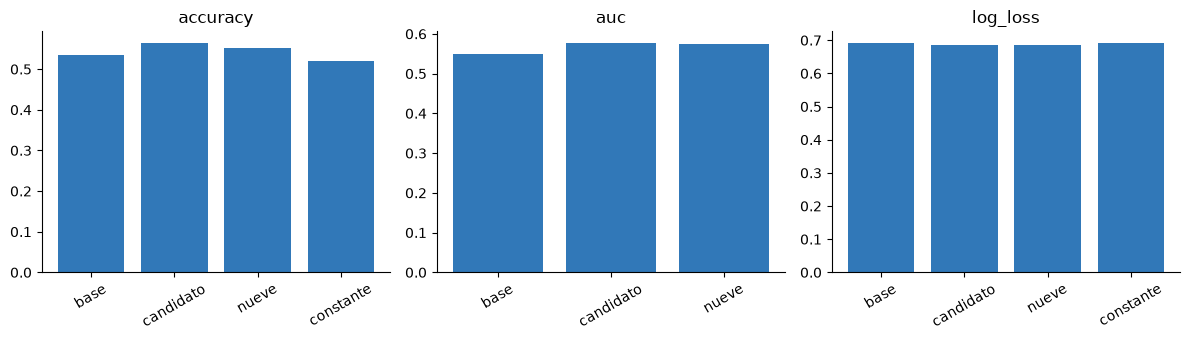

In [4]:
first = predict.evaluate_new(base, candidate, base_table, candidate_table)
assert first['n'] == 1767
metrics = pd.DataFrame(first['modelos']).T
display(metrics[['accuracy', 'accuracy_ic95', 'auc', 'auc_ic95', 'log_loss']])
# Fuente: data/models/prueba_final.json, primera ejecución 2026-11-09T18:09:00+00:00.
expected = {'candidato': [.5647990945104697, .5774866973148212, .6847082579283519],
            'base': [.5342388228636107, .549107635600116, .691665623320615],
            'nueve': [.5517826825127334, .5742742881491236, .684867010372854]}
for name, values in expected.items():
    np.testing.assert_allclose([first['modelos'][name][key] for key in ['accuracy', 'auc', 'log_loss']],
                               values, rtol=0, atol=5e-4, err_msg='El reajuste no reproduce la prueba guardada; detenerse.')
np.testing.assert_allclose([first['modelos']['constante']['accuracy'], first['modelos']['constante']['log_loss']],
                           [.5212224108658744, .6922467799222685], rtol=0, atol=5e-4)
print('Reproducción verificada (tolerancia absoluta 0,0005).')
print('Diferencia emparejada:', first['diferencias']['log_loss'])
print(first['veredicto'])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, metric in zip(axes, ['accuracy', 'auc', 'log_loss']):
    values = pd.to_numeric(metrics[metric], errors='coerce')
    ax.bar(values.index, values, color='#3178b8'); ax.set_title(metric); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
test = candidate_table[~candidate_table.match_id.astype(str).isin(dev.match_id.astype(str)) &
                       (candidate_table.game_start_ts > candidate['last_match_ts'])].sort_values(['game_start_ts', 'match_id'], kind='stable')
base_test = base_table.set_index(base_table.match_id.astype(str)).loc[test.match_id.astype(str)]
y = test.blue_win.to_numpy()
probabilities = {'candidato': candidate['model'].predict_proba(test[candidate['features']])[:, 1],
                 'base': base['model'].predict_proba(base_test[base_features])[:, 1]}

## 5. Predicción selectiva y calibración (post-hoc)
Se reutiliza la primera prueba: esto **no es una segunda prueba**. Confianza = max(p, 1−p), con umbrales 0,55 / 0,60 / 0,65. Los intervalos Wilson son condicionales al subconjunto seleccionado. Subconjuntos diferentes no permiten una comparación emparejada de modelos. ECE usa diez bins de igual ancho; el gráfico usa deciles de igual frecuencia. Recalibración logística conjunta de intercepto y pendiente: ideal 0 y 1. No se sustituye el predictor por uno recalibrado. IC por 200 remuestreos de partidas para limitar tiempo; el análisis original usó 500.

,threshold,n,coverage,accuracy,lo,hi,modelo
0,0.55,975,0.551783,0.583590,0.552378,0.614146,candidato
1,0.60,414,0.234295,0.601449,0.553563,0.647470,candidato
2,0.65,140,0.079230,0.592857,0.510050,0.670704,candidato
3,0.55,1002,0.567063,0.553892,0.522966,0.584407,base
4,0.60,468,0.264856,0.594017,0.548935,0.637568,base
5,0.65,177,0.100170,0.627119,0.553888,0.694949,base


,modelo,medida,estimate,ic95
0,candidato,brier,0.245742,"(0.24167047931614027, 0.24983957250705482)"
1,candidato,ece,0.016218,"(0.01025419177176283, 0.04390425403128226)"
2,candidato,intercept,-0.030476,"(-0.13463023814941924, 0.07478812140330687)"
3,candidato,slope,0.766084,"(0.493359392488888, 1.0758979324156268)"
4,base,brier,0.249181,"(0.2453769539497448, 0.2537043523130968)"
5,base,ece,0.037954,"(0.02004411441196144, 0.07134944993582214)"
6,base,intercept,-0.040457,"(-0.13790742080900323, 0.054653505707404605)"
7,base,slope,0.513849,"(0.2315985547191035, 0.7562678512910865)"


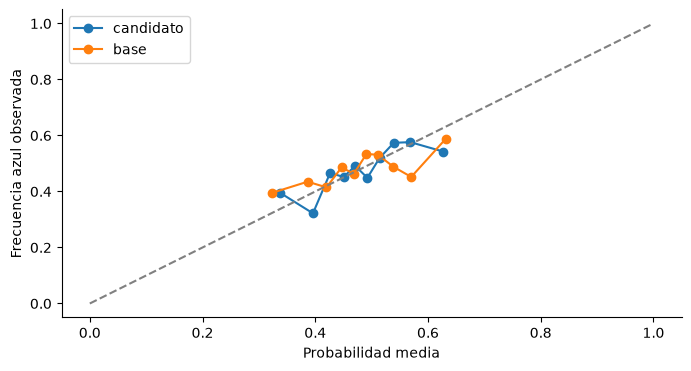

ECE candidato con 10/15/20 bins: [0.0162, 0.0128, 0.0281]


In [5]:
selective = pd.concat([train.selective_accuracy(y, p).assign(modelo=name) for name, p in probabilities.items()], ignore_index=True)
display(selective)
calibration = {name: train.calibration_summary(y, p, n_boot=200) for name, p in probabilities.items()}
display(pd.DataFrame([dict(modelo=name, medida=measure, **value) for name, values in calibration.items()
                      for measure, value in values.items()]))
fig, ax = plt.subplots()
for name, p in probabilities.items():
    reliability = pd.DataFrame({'p': p, 'y': y, 'decil': pd.qcut(p, 10, labels=False, duplicates='drop')}).groupby('decil').agg(p=('p', 'mean'), observada=('y', 'mean'), n=('y', 'size'))
    ax.plot(reliability.p, reliability.observada, 'o-', label=name)
ax.plot([0, 1], [0, 1], '--', color='gray'); ax.set(xlabel='Probabilidad media', ylabel='Frecuencia azul observada')
ax.legend(); plt.show()
print('ECE candidato con 10/15/20 bins:', [round(train.calibration_summary(y, probabilities['candidato'], n_bins=b, n_boot=1)['ece']['estimate'], 4) for b in [10, 15, 20]])

## 6. Factores asociados
El modelo final se reajusta descriptivamente en las 2.973 partidas, con pool de todas ellas. Sus coeficientes no son una prueba independiente. OR por desviación estándar, con 200 remuestreos que reajustan imputación, escala y coeficientes al C elegido. La permutación usa exclusivamente el candidato congelado sobre la prueba: 20 permutaciones por variable, IC con 200 remuestreos emparejados de partidas y elección de una permutación. No hay interpretación causal. Experiencia con campeón es limítrofe: su IC de caída de AUC incluye cero en el análisis original y lo excluye en la revisión independiente. Correlación entre variables reparte su crédito.

,variable,OR,IC inferior,IC superior
0,dif_winrate_10,0.864195,0.802506,0.951082
1,dif_partidas_con_campeon,1.143049,1.059550,1.244685
2,dif_racha,1.048818,0.957307,1.120614
3,dif_log_dias_desde_ultima,0.942753,0.871881,1.016980
4,dif_kda_medio,1.173603,1.097998,1.264769
5,dif_partidas_previas,1.038916,0.961047,1.140314
6,dif_sin_historial,1.042645,0.957225,1.159404
7,dif_kills_medio,1.251579,1.148524,1.358034
8,dif_partidas_24h,1.058070,0.990538,1.157569
9,dif_winrate_campeon_posicion,1.091945,1.022427,1.179805


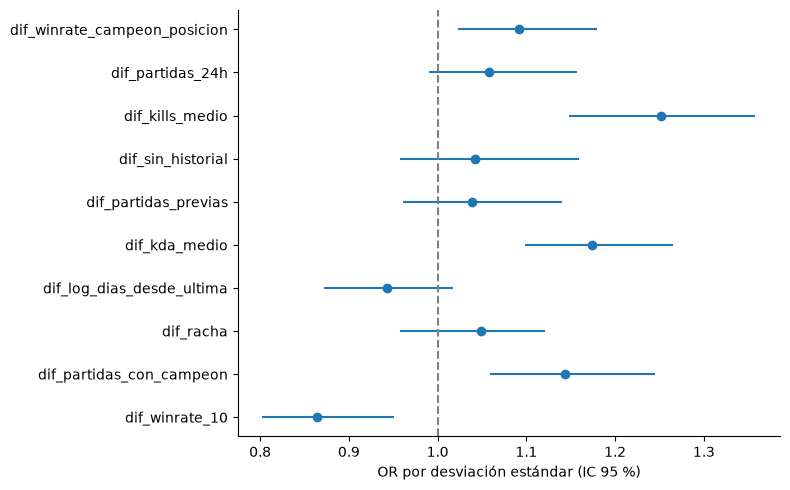

,variable,caida_AUC,IC_AUC,aumento_log_loss,IC_log_loss
0,dif_winrate_10,0.007274,"[-0.008064380984518291, 0.022491478186189715]",3.281741e-03,"[-0.001767614325489368, 0.008759749639225453]"
1,dif_partidas_con_campeon,0.022190,"[0.006194460832070617, 0.04075847219384745]",5.961736e-03,"[0.0013401231996493222, 0.010661665494281622]"
2,dif_racha,0.004195,"[-0.007844805969475835, 0.01777862848089449]",1.453740e-03,"[-0.0019164204792395825, 0.004665334929859418]"
3,dif_log_dias_desde_ultima,-0.007511,"[-0.02332730283154908, 0.012248616541507135]",-2.522558e-03,"[-0.007820027234430964, 0.00335046662625212]"
4,dif_kda_medio,0.033172,"[0.007678406541436669, 0.06099527354109631]",9.479429e-03,"[0.003213663675023445, 0.01689340013122874]"
5,dif_partidas_previas,0.001095,"[-0.0020044827536240704, 0.003920014418047699]",3.328006e-04,"[-0.0004882693369511006, 0.0011782100382748228]"
6,dif_sin_historial,-0.000488,"[-0.006216103991596042, 0.00586994011799449]",-4.277584e-07,"[-0.0018544685935458253, 0.0016554773848840624]"
7,dif_kills_medio,0.028623,"[0.012627904811496594, 0.04954447847297384]",6.917865e-03,"[0.002446874141880008, 0.012646674042467181]"
8,dif_partidas_24h,-0.004641,"[-0.018726771807349097, 0.00876835401666457]",-2.052284e-03,"[-0.005739630313819832, 0.0016829328670365093]"
9,dif_winrate_campeon_posicion,0.004115,"[-0.007219744525770119, 0.013128168337538944]",5.167742e-04,"[-0.002200558206623396, 0.0030928705861408344]"


,liga,n_inferior,n_superior,victoria_inferior,victoria_superior
0,Hierro a Platino,110,105,0.363636,0.561905
1,Esmeralda y Diamante,56,61,0.464286,0.573770
2,Maestro o superior,189,188,0.391534,0.563830


In [6]:
all_pool, all_shares = predict._pool_and_shares(history, done.match_id.astype(str))
final_table = predict._table_for(DATA_DIR, all_pool, all_shares).sort_values('game_start_ts', kind='stable')
features = list(build.FINAL_FEATURES)
final_search = predict._fit_logistic(final_table, features)
final_model = final_search.best_estimator_
assert final_search.best_params_ == {'model__C': .01}
rng = np.random.default_rng(42)
coefficients = []
for _ in range(200):
    sample = final_table.iloc[rng.integers(len(final_table), size=len(final_table))]
    model = clone(final_model)
    model.fit(sample[features], sample.blue_win, model__sample_weight=train.tier_weights(sample.seed_tier))
    coefficients.append(model.named_steps['model'].coef_[0])
intervals = np.exp(np.percentile(coefficients, [2.5, 97.5], axis=0))
coef_table = pd.DataFrame({'variable': features, 'OR': np.exp(final_model.named_steps['model'].coef_[0]),
                           'IC inferior': intervals[0], 'IC superior': intervals[1]})
display(coef_table)
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(coef_table.OR, coef_table.variable, xerr=[coef_table.OR-intervals[0], intervals[1]-coef_table.OR], fmt='o')
ax.axvline(1, ls='--', color='gray'); ax.set_xlabel('OR por desviación estándar (IC 95 %)'); plt.tight_layout(); plt.show()
X = test[features].reset_index(drop=True)
p = probabilities['candidato']
loss = lambda q: -(y*np.log(np.clip(q, 1e-6, 1-1e-6))+(1-y)*np.log1p(-np.clip(q, 1e-6, 1-1e-6)))
permutations = []
for col in features:
    qs = []
    for _ in range(20):
        xp = X.copy(); xp[col] = rng.permutation(xp[col].to_numpy())
        qs.append(candidate['model'].predict_proba(xp)[:, 1])
    aucs = [roc_auc_score(y, p)-roc_auc_score(y, q) for q in qs]
    losses = [(loss(q)-loss(p)).mean() for q in qs]
    boot_auc, boot_ll = [], []
    for _ in range(200):
        i = rng.integers(len(y), size=len(y)); q = qs[rng.integers(len(qs))]
        if len(np.unique(y[i])) == 2:
            boot_auc.append(roc_auc_score(y[i], p[i])-roc_auc_score(y[i], q[i]))
        boot_ll.append((loss(q)[i]-loss(p)[i]).mean())
    permutations.append(dict(variable=col, caida_AUC=np.mean(aucs), IC_AUC=np.percentile(boot_auc, [2.5, 97.5]),
                             aumento_log_loss=np.mean(losses), IC_log_loss=np.percentile(boot_ll, [2.5, 97.5])))
display(pd.DataFrame(permutations))
v = test.dif_kills_medio; low, high = v.quantile([.2, .8])
contrasts = []
for band, tiers in train.TIER_BANDS.items():
    mask = test.seed_tier.isin(tiers)
    bottom, top = mask & (v <= low), mask & (v >= high)
    contrasts.append(dict(liga=band, n_inferior=int(bottom.sum()), n_superior=int(top.sum()),
                          victoria_inferior=test.loc[bottom, 'blue_win'].mean(), victoria_superior=test.loc[top, 'blue_win'].mean()))
display(pd.DataFrame(contrasts))

## 7. Draft
El análisis del 2026-11-09 probó **una sola** variable: diferencia de tasa media global de victoria de campeones, con pool local disponible antes del juego. Ganancia de pérdida logarítmica CV −0,000065 (p corregido 0,20), walk-forward −0,000107 en 2.475 predicciones. No se retuvo; no hay objetivo de potencia para un efecto no positivo. El preregistro se corrigió antes de calcular resultados para respetar disponibilidad. Aquí no se recalcula. Este resultado no evalúa balance AD/AP, tanques, melee, enfrentamientos de línea ni parche, y no demuestra que el draft carezca de importancia.

## 8. Segunda prueba (pendiente)
Preregistrada el 2026-11-09 en NOTES.md. El comando `--evaluate-final` carga el modelo final guardado sin reajustarlo. Excluye sus 2.973 IDs de entrenamiento y los IDs de desarrollo, y exige fecha estrictamente posterior tanto al último entrenamiento como al 2026-11-05 18:00 UTC. Compara contra su tasa azul constante: gana solo si el IC 95 % emparejado de constante menos final en pérdida logarítmica queda enteramente sobre cero. El candidato sirve de referencia de deriva. Este notebook solo muestra el registro opcional; **nunca ejecuta esa prueba**.

In [7]:
second_path = next((p for p in [Path('segunda_prueba.json'), DATA_DIR / 'segunda_prueba.json',
                               REPO / 'data/models/segunda_prueba.json'] if p.is_file()), None)
runs = json.loads(second_path.read_text(encoding='utf-8')).get('runs', []) if second_path else []
if runs:
    last = runs[-1]
    print('Segunda prueba:', last['fecha'], '| n =', last['n'])
    display(pd.DataFrame(last['modelos']).T)
    print(last['veredicto'])
else:
    print('Segunda prueba pendiente: no se encontró segunda_prueba.json.')

Segunda prueba pendiente: no se encontró segunda_prueba.json.


## 9. Programa
Tras terminar la recolección, detenerla y exportar, se ejecuta `python -m src.models.predict --evaluate-final` una vez, sin más reentrenamiento previsto. Para una partida en curso: `python -m src.models.predict --live "NAME#TAG"`. Necesita clave Riot y un jugador en solo/duo; lee diez historiales y registra la predicción. Nunca se ejecuta a la vez que el recolector. El programa advierte que la señal es débil: la AUC temporal es optimista y la primera prueba corresponde al candidato, no al final reajustado. Si existe la segunda prueba, muestra la AUC independiente del final.

## 10. Conclusiones y limitaciones
El candidato supera a la base en la primera prueba, con señal débil (AUC aproximadamente 0,58). La selección por confianza reduce cobertura a cambio de una mejora modesta de accuracy. La pendiente de calibración del candidato admite 1; la base muestra más sobreconfianza. ECE depende de bins. Kills previos muestran la asociación más estable (se mantiene en las tres bandas de liga); KDA es fuerte en conjunto pero no se aprecia en Esmeralda y Diamante; experiencia con campeón tiene evidencia limítrofe. Win rate condicionado a kills/KDA puede tener coeficiente negativo sin implicar causalidad.

Aproximadamente 58 % de la prueba es Maestro o superior. Jugadores repetidos introducen agrupamiento no modelado: los IC por partidas pueden ser optimistas. Liga actual no equivale a liga histórica. El pool congelado envejece, hay cambios de parche y selección de variables en desarrollo. El modelo final aún necesita su prueba independiente nueva; no se modifica por este análisis.

In [8]:
print(f'Ejecución completa en {(time.monotonic()-STARTED)/60:.1f} minutos. No se guardaron modelos ni registros de pruebas.')

Ejecución completa en 0.9 minutos. No se guardaron modelos ni registros de pruebas.
